In [65]:
import tqdm
import math
import torch
import numpy as np
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

In [66]:
x0_npy = np.load("../data/trajectories_npy/test01/G1_to_S/x0.npy")
x1_npy = np.load("../data/trajectories_npy/test01/G1_to_S/x1.npy")

In [67]:
class Block(nn.Module):
    def __init__(self, channels=512):
        super().__init__()
        self.ff = nn.Linear(channels, channels)
        self.act = nn.ReLU()

    def forward(self, x):
        return self.act(self.ff(x))

class MLP(nn.Module):
    def __init__(self, channels_data=2, layers=5, channels=512, channels_t=512):
        super().__init__()
        self.channels_t = channels_t
        self.in_projection = nn.Linear(channels_data, channels)
        self.t_projection = nn.Linear(channels_t, channels)
        self.blocks = nn.Sequential(*[
            Block(channels) for _ in range(layers)
        ])
        self.out_projection = nn.Linear(channels, channels_data)

    def gen_t_embedding(self, t, max_positions=10000):
        t = t * max_positions
        half_dim = self.channels_t // 2
        emb = math.log(max_positions) / (half_dim - 1)
        emb = torch.arange(half_dim, device=t.device).float().mul(-emb).exp()
        emb = t[:, None] * emb[None, :]
        emb = torch.cat([emb.sin(), emb.cos()], dim=1)
        if self.channels_t % 2 == 1:  # zero pad
            emb = nn.functional.pad(emb, (0, 1), mode='constant')
        return emb

    def forward(self, x, t):
        x = self.in_projection(x)
        t = self.gen_t_embedding(t)
        t = self.t_projection(t)
        x = x + t
        x = self.blocks(x)
        x = self.out_projection(x)
        return x

# Train or load model

## Train model

In [92]:
model = MLP(layers=5, channels_data=7974, channels=512)
optim = torch.optim.AdamW(model.parameters(), lr=1e-4)

In [93]:
data_x0 = torch.from_numpy(x0_npy[:-1, :]).float()
data_x1 = torch.from_numpy(x1_npy[:-1, :]).float()

n_samples = len(x0)
indices = torch.randperm(n_samples)

# Split indices (80/20)
train_size = int(0.8 * n_samples)
train_idx, test_idx = indices[:train_size], indices[train_size:]

# Slice tensors
x0_train, x1_train = x0[train_idx], x1[train_idx]
x0_test, x1_test = x0[test_idx], x1[test_idx]

training_steps = 500
batch_size = 10
pbar = tqdm.tqdm(range(training_steps))
losses_train = []
losses_test = []
for i in pbar:
    # calculate train loss
    ids = torch.randint(x0_train.size(0), (batch_size,))
    x0 = x0_train[ids]
    x1 = x1_train[ids]
    target = x1 - x0
    t = torch.rand(x1.size(0))
    xt = (1 - t[:, None]) * x0 + t[:, None] * x1
    pred = model(xt, t)
    loss_train = ((target - pred)**2).mean()

    # calculate test loss
    target = x1_test - x0_test
    t = torch.rand(x1_test.size(0))
    xt = (1 - t[:, None]) * x0_test + t[:, None] * x1_test
    pred = model(xt, t)
    loss_test = ((target - pred)**2).mean()

    # train
    loss_train.backward()
    optim.step()
    optim.zero_grad()
    pbar.set_postfix(loss=loss_train.item())
    losses_train.append(loss_train.item())
    losses_test.append(loss_test.item())
    
    

100%|████████████████████████████| 500/500 [00:27<00:00, 17.99it/s, loss=0.0528]


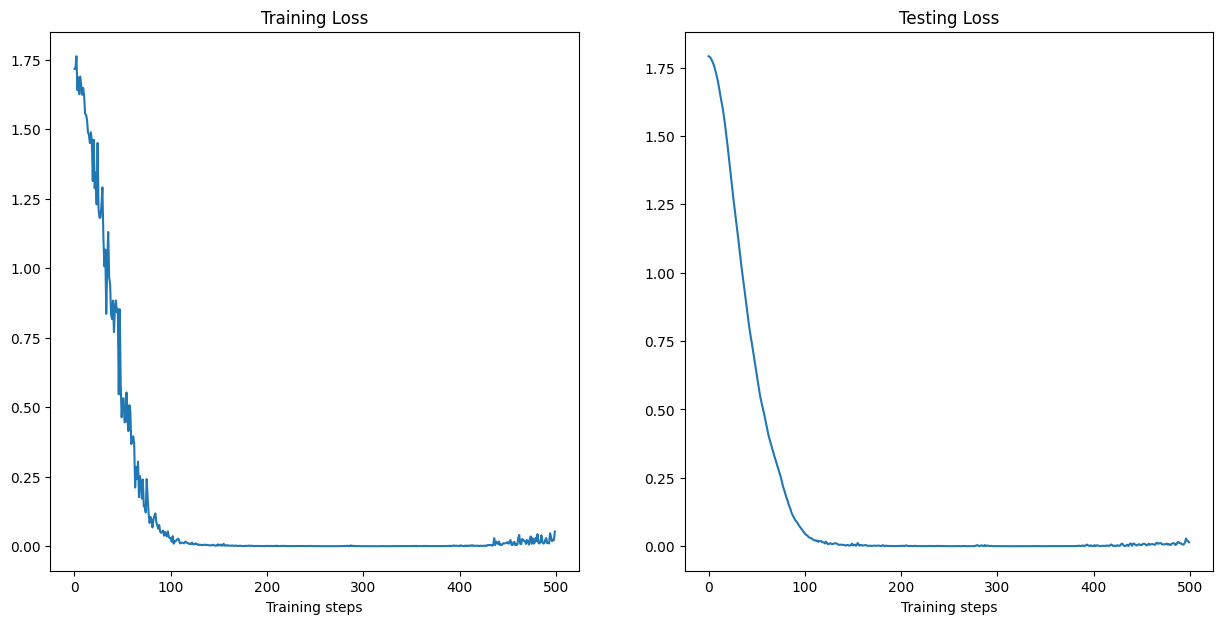

In [94]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
ax[0].plot(losses_train)
ax[0].set_title("Training Loss")
ax[0].set_xlabel("Training steps")
ax[1].plot(losses_test)
ax[1].set_title("Testing Loss")
ax[1].set_xlabel("Training steps")

plt.show()

In [96]:
# Save trained model:
torch.save(model.state_dict(), "../models/model_test01.pt")

## Load preexisting model

In [4]:
# Load preptrained model:
model = MLP(layers=5, channels_data=7974, channels=512)
optim = torch.optim.AdamW(model.parameters(), lr=1e-4)
ckpt = torch.load("../models/model_test01.pt")
model.load_state_dict(ckpt)

<All keys matched successfully>

# Iterate trajectory through the vector field

In [5]:
def iterate_trajectory(model, x0, time_steps=100, lr=0.1):
    time_steps = np.linspace(0, 1, time_steps)
    x_curr = x0.copy()
    structures = []
    for i, t in enumerate(time_steps):
        v = model(torch.Tensor(x_curr), torch.Tensor([t])).detach().numpy()
        x_curr = x_curr + v*lr
        if i%10==0:
            structures.append(x_curr)
    return structures

In [113]:
struct_id = 0
x0_vec = x0_npy[struct_id,:]
x1_vec = x1_npy[struct_id,:]
x0_3d =  x0_vec.reshape((int(len(x0_vec)/3), 3))
x1_3d =  x1_vec.reshape((int(len(x1_vec)/3), 3))
structures = iterate_trajectory(model, x0_vec, time_steps=100, lr=0.01)

In [109]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
from src.md.visualization_utils import visualize_whole_genome, create_gif

In [114]:
axis_ranges = [x0_3d[:,0].min(), x0_3d[:,0].max(),
               x0_3d[:,1].min(), x0_3d[:,1].max(),
               x0_3d[:,2].min(), x0_3d[:,2].max()]

In [115]:
figs = [visualize_whole_genome(
            points.reshape((int(points.shape[1]/3), 3)), 
            diploid=True, resolution=2_000_000, p=0, title=f"Frame {i}", 
            fig_show=False, axis_range=axis_ranges) \
        for i, points in enumerate(structures)]

In [116]:
create_gif(figs, "./animation.gif", duration=300)

100%|███████████████████████████████████████████| 10/10 [00:15<00:00,  1.54s/it]


# Analyse the iterated trajectory

In [42]:
def rmsd_direct(A: np.ndarray, B: np.ndarray) -> float:
    """Compute direct RMSD between two (m, 3) point sets."""
    return np.sqrt(np.mean(np.sum((A - B) ** 2, axis=1)))

In [117]:
rmsds = [rmsd_direct(struct.reshape((int(struct.shape[1]/3),3)), x1_3d) for struct in structures]

[]

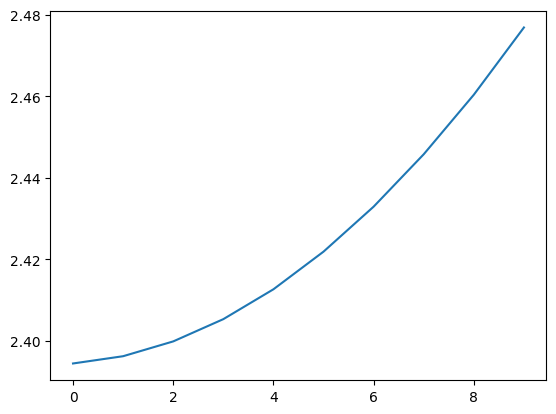

In [118]:
plt.plot(rmsds)
plt.plot()

# Analyse velocity field

In [262]:
struct_id = 0
x0_vec = x0_npy[struct_id,:]
x1_vec = x1_npy[struct_id,:]
x0_3d =  x0_vec.reshape((int(len(x0_vec)/3), 3))
x1_3d =  x1_vec.reshape((int(len(x1_vec)/3), 3))
structures = iterate_trajectory(model, x0_vec, time_steps=400, lr=0.1)

In [263]:
def get_velocity_field(model, x_vec, point_id, coord_id, v_min, v_max, t_points, matrix_size=20):
    x = np.linspace(v_max, v_min, matrix_size)
    t = np.linspace(0, 1, t_points)
    v_field = np.zeros((matrix_size, t_points))

    diff_vec = np.zeros(x_vec.shape)
    for i in range(matrix_size):
        for j in range(t_points):
            diff_vec[point_id*3+coord_id] = x[i]
            v = model(torch.Tensor(x_vec + diff_vec), torch.Tensor([t[j]])).detach().numpy()[0, coord_id]
            v_field[i, j] = v
    return v_field

def get_trajectory(structures, point_id, coord_id):
    return [struct[point_id*3+coord_id] for struct in structures] 


def convert_to_heatmap_coords(values, v_min, v_range, matrix_size):
    return (1-(values-v_min)/v_range)*(matrix_size-1) + 0.5

def plot_velocity_fields(model, structures, x1_vec, n_points=2, matrix_size=20):

    velocities = []
    differences = []
    
    fig, ax = plt.subplots(n_points, 3, figsize=(15, 10))
    for i in range(n_points):
        for j in range(3):
            values = np.array([struct[0,3*i+j] for struct in structures] + [x1_vec[3*i+j]], dtype=float)
            v_min = np.min(values)
            v_max = np.max(values)
            v_range = v_max - v_min
            v_min -= v_range*0.1
            v_max += v_range*0.1
            v_range = v_max - v_min
            v_field = get_velocity_field(model, structures[0][0], i, j, v_min, v_max, t_points=len(structures), matrix_size=matrix_size)

            if i==0 and j==1:
                for k in range(len(structures)-1):
                    velocities.append(v_field[0, k])
                    differences.append(structures[k+1][0,3*i+j] - structures[k][0,3*i+j])
            
            sns.heatmap(v_field, cmap="viridis", ax=ax[i][j])
            ax[i][j].set_title(f"Point {i}, coord {j}")
            ax[i][j].plot(
                np.arange(len(values)-1) + 0.5,
                convert_to_heatmap_coords(values[:-1], v_min, v_range, matrix_size),
                color="white", marker="o", markersize=8, linewidth=2, linestyle="-", label="Trajectory",
            )
            
            ax[i][j].plot(
                np.array([-0.5, len(structures)+0.5]),
                convert_to_heatmap_coords(np.array([structures[0][0, 3*i+j], structures[0][0, 3*i+j]]), v_min, v_range, matrix_size),
                color="white", linewidth=2, linestyle="--", label="x0",
            )
            ax[i][j].plot(
                np.array([-0.5, len(structures)+0.5]),
                convert_to_heatmap_coords(np.array([x1_vec[3*i+j], x1_vec[3*i+j]]), v_min, v_range, matrix_size),
                color="white", linewidth=2, linestyle="--", label="x1",
            )
    plt.show()
    return velocities, differences

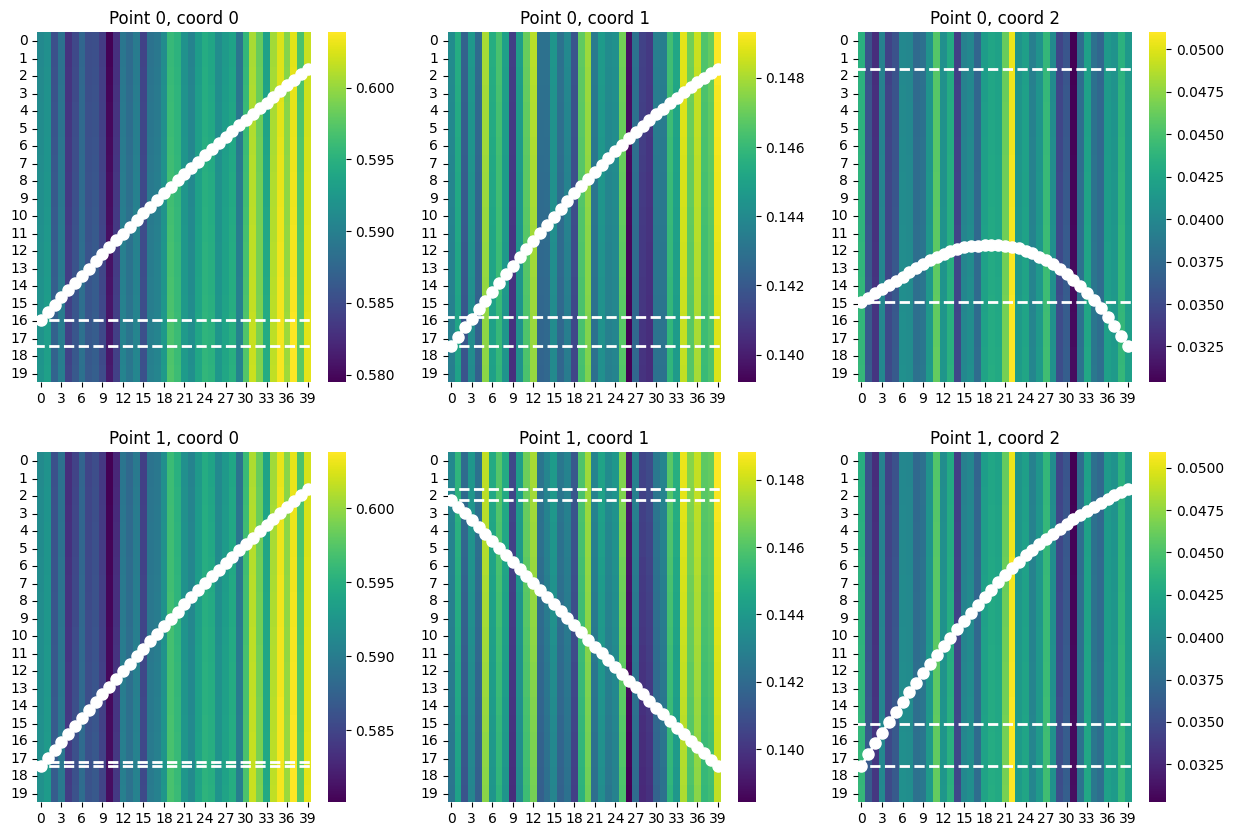

In [264]:
velocities, differences = plot_velocity_fields(model, structures, x1_vec, n_points=2)

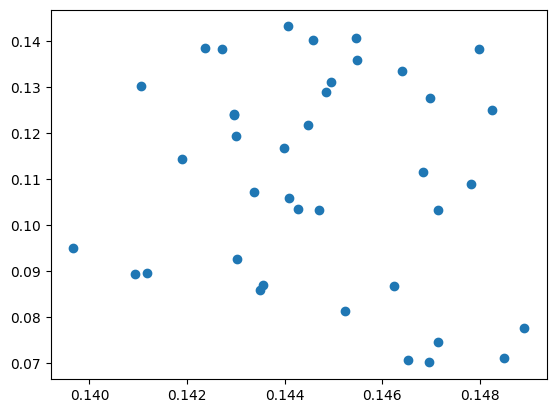

In [265]:
plt.scatter(velocities, differences)
plt.show()

In [119]:
row_id = np.random.randint(x0_npy.shape[0])
coord_id = np.random.randint(x0_npy.shape[1])
x_radius = 10

n = 30
x = np.linspace(x0_npy[row_id, coord_id]-x_radius, x0_npy[row_id, coord_id]+x_radius, n)
t = np.linspace(0, 1, n)
v_field = np.zeros((n, n))

x0_row = x0_npy[row_id,:].copy()
for i in range(n):
    for j in range(n):
        v = model(torch.Tensor(x0_row + x[i]), torch.Tensor([t[j]])).detach().numpy()[0, coord_id]
        v_field[i, j] = v

print(f"Starting value: { x0_npy[row_id, coord_id] }")
print(f"Ending value: { x1_npy[row_id, coord_id] }")


Strating value: -3.549
Ending value: -4.117


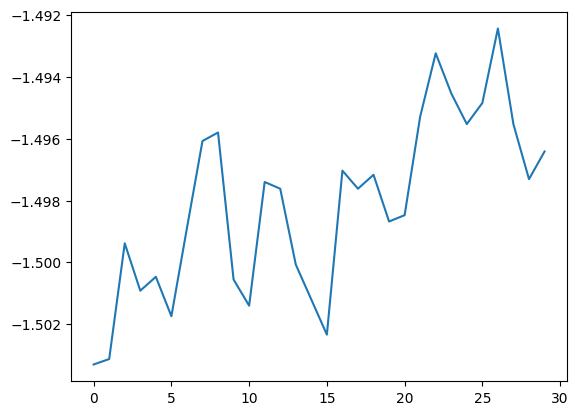

In [178]:
plt.plot(v_field[15,:])

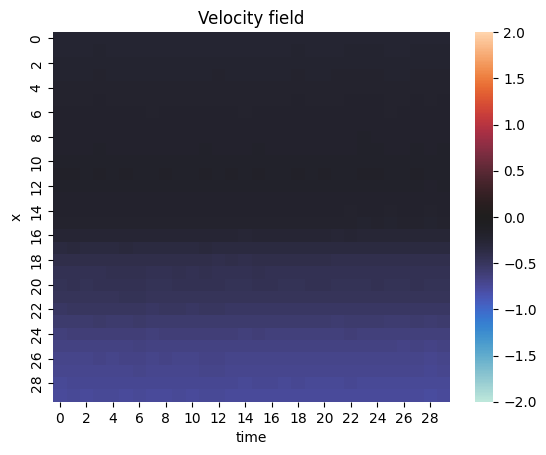

In [120]:
sns.heatmap(v_field, vmin=-2, vmax=2, cmap="icefire")
plt.title("Velocity field")
plt.xlabel("time")
plt.ylabel("x")
plt.show()

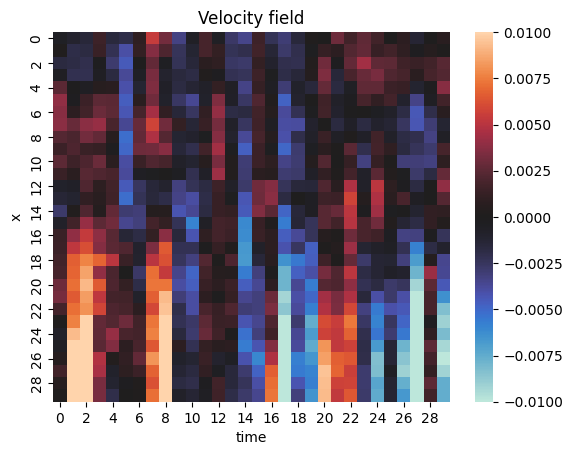

In [184]:
sns.heatmap(v_field -v_field.mean(axis=1, keepdims=True), vmin=-0.01, vmax=0.01, cmap="icefire")
plt.title("Velocity field")
plt.xlabel("time")
plt.ylabel("x")
plt.show()